# Bias-Aware Employee Attrition: analysis notebook

**Question.** Which employees are most likely to leave voluntarily, what drives that, and does a model built to find them treat gender, race and age groups fairly?

**Data.** `data/Messy_HR_Dataset_Detailed.csv`: a *synthetic* HR dataset (3,150 rows, 39 columns) with deliberately messy dates and fields. Findings describe this dataset, not a real organisation.

**What this notebook does**
1. Audits the data (duplicates, contradictory fields, impossible dates)
2. Defines the cohort and the label
3. Explores where attrition is concentrated, with confidence intervals
4. Compares models by cross-validation, then evaluates once on a held-out test set
5. Explains predictions with SHAP and turns them into per-employee drivers
6. Audits fairness on gender, race and age band, and tests the fairness/accuracy trade-off
7. Exports the CSVs that feed the Tableau dashboards in `outputs/`

Run top to bottom (about one minute). Every number quoted in the README and dashboards comes from this notebook.

## 0. Setup

In [1]:
import json
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "Messy_HR_Dataset_Detailed.csv"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
FLAG_TOP_PCT = 0.20  # HR capacity assumption: review the highest-risk 20%
HIGH_PCT, MED_PCT = 0.10, 0.30  # risk bands: top 10% High, next 20% Medium

summary = {}

FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GREY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110})


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    m = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - m) / d, (c + m) / d)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data audit

Before modelling, check whether the data can be trusted. Two things to look for: duplicate records, and fields that should agree but don't.

In [2]:
raw = pd.read_csv(DATA)
summary["rows_raw"] = len(raw)
df = raw.drop(columns=["Unnamed: 0"]).drop_duplicates().copy()
summary["exact_duplicate_rows_removed"] = len(raw) - len(df)
assert df["Employee ID"].is_unique

for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip()

df["start"] = pd.to_datetime(df["StartDate"], format="%d-%b-%y")
df["survey"] = pd.to_datetime(df["Survey Date"], format="%d-%m-%Y")
df["train"] = pd.to_datetime(df["Training Date"], format="%d-%b-%y")
df["dob"] = pd.to_datetime(df["DOB"], format="%d-%m-%Y")

df["tenure_years"] = (df["survey"] - df["start"]).dt.days / 365.25
df["days_train_to_survey"] = (df["survey"] - df["train"]).dt.days  # signed
df["age"] = (df["survey"] - df["dob"]).dt.days / 365.25  # audit only, not a feature
summary["dq_negative_tenure_rows"] = int((df["tenure_years"] < 0).sum())
summary["dq_training_after_survey_rows"] = int((df["days_train_to_survey"] < 0).sum())
summary["dq_status_active_but_has_exit_date"] = int(
    ((df["EmployeeStatus"] == "Active") & df["ExitDate"].notna()).sum()
)

In [3]:
print("Raw rows:", summary["rows_raw"], "| exact duplicates removed:", summary["exact_duplicate_rows_removed"],
      "| unique employees:", len(df))
print("Negative tenure at survey date:", summary["dq_negative_tenure_rows"], "rows")
print("Training dated after the survey:", summary["dq_training_after_survey_rows"], "rows")
print("'Active' employees that have an ExitDate:", summary["dq_status_active_but_has_exit_date"], "rows")

print("\nEmployeeStatus vs whether an ExitDate exists:")
print(pd.crosstab(df["EmployeeStatus"], df["ExitDate"].notna().map({True: "has ExitDate", False: "no ExitDate"})))
print("\nEmployeeStatus vs TerminationType:")
print(pd.crosstab(df["EmployeeStatus"], df["TerminationType"]))

Raw rows: 3150 | exact duplicates removed: 150 | unique employees: 3000
Negative tenure at survey date: 287 rows
Training dated after the survey: 1480 rows
'Active' employees that have an ExitDate: 991 rows

EmployeeStatus vs whether an ExitDate exists:
ExitDate                has ExitDate  no ExitDate
EmployeeStatus                                   
Active                           991         1467
Future Start                      69            0
Leave of Absence                  86            0
Terminated for Cause              66            0
Voluntarily Terminated           321            0

EmployeeStatus vs TerminationType:
TerminationType         Involuntary  Resignation  Retirement   Unk  Voluntary
EmployeeStatus                                                               
Active                          244          252         244  1467        251
Future Start                     18           11          23     0         17
Leave of Absence                 19           21

**What the audit shows**

- 150 rows are exact duplicates. If they are kept, the same employee can land in both the training and test sets, which inflates test scores. They are removed.
- `EmployeeStatus`, `ExitDate` and `TerminationType` contradict each other: hundreds of "Active" employees have exit dates and termination types, and employees marked "Voluntarily Terminated" carry types like "Retirement" and "Involuntary".
- A large share of dates are impossible or odd (training after the survey, negative tenure).

**Decision.** `EmployeeStatus` is the only field used for the label, because it is the only one with a clean, mutually exclusive category set. `ExitDate` and `TerminationType` are used for nothing. Negative-tenure and training-after-survey rows are kept but flagged with indicator features rather than silently clipped, so the model and the audit can see them.

## 2. Cohort and label

- **Label (`left`)**: `EmployeeStatus == "Voluntarily Terminated"`.
- **Excluded**: "Terminated for Cause" (employer-initiated, not flight risk) and "Future Start" (not yet employed).
- **Kept as not-left**: "Active" and "Leave of Absence".

The data has no consistent time window, so the label means *has voluntarily left*, not *will leave within N months*. The model ranks people by resemblance to past leavers.

In [4]:
# Flight risk = voluntary exit. 'Terminated for Cause' is employer-initiated and
# 'Future Start' has not started, so both are excluded from the modelling cohort.
# No consistent time window exists in the data, so the label is "has voluntarily
# left", not "will leave within N months".
df = df[~df["EmployeeStatus"].isin(["Future Start", "Terminated for Cause"])].copy()
df["left"] = (df["EmployeeStatus"] == "Voluntarily Terminated").astype(int)
summary["cohort_rows"] = len(df)
summary["cohort_leavers"] = int(df["left"].sum())
summary["cohort_attrition_rate"] = round(df["left"].mean(), 4)

In [5]:
print("Cohort:", summary["cohort_rows"], "employees |", summary["cohort_leavers"], "voluntary leavers |",
      f'{summary["cohort_attrition_rate"]:.1%} attrition')
df["EmployeeStatus"].value_counts().to_frame("employees")

Cohort: 2865 employees | 321 voluntary leavers | 11.2% attrition


,employees
EmployeeStatus,
Active,2458
Voluntarily Terminated,321
Leave of Absence,86


## 3. Where is attrition concentrated?

Rates are shown with 95% Wilson confidence intervals. Small groups produce wide intervals and should not be over-read.

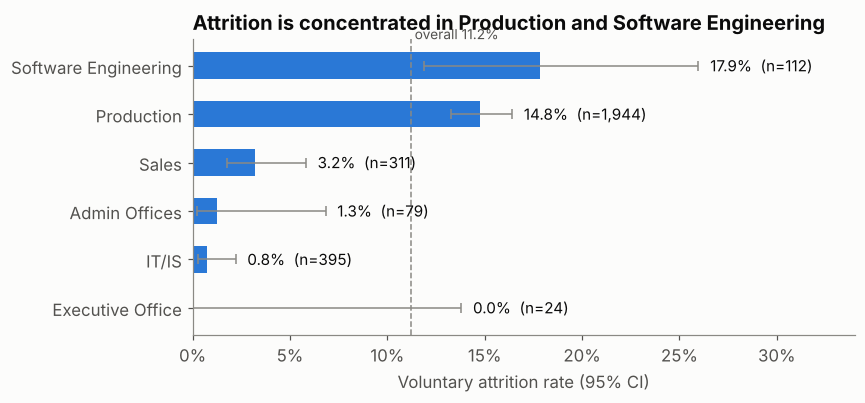

,leavers,n,rate,lo,hi
DepartmentType,,,,,
Executive Office,0,24,0.000,0.000,0.138
IT/IS,3,395,0.008,0.003,0.022
Admin Offices,1,79,0.013,0.002,0.068
Sales,10,311,0.032,0.018,0.058
Production,287,1944,0.148,0.133,0.164
Software Engineering,20,112,0.179,0.119,0.260


In [6]:
eda = df.copy()
eda["tenure_band"] = pd.cut(eda["tenure_years"].clip(lower=0), [-0.01, 1, 2, 3, 4, 10],
                            labels=["<1 yr", "1-2 yrs", "2-3 yrs", "3-4 yrs", "4+ yrs"]).astype(str)
overall = eda["left"].mean()


def rate_tbl(col, order=None):
    t = eda.groupby(col)["left"].agg(["sum", "size"]).rename(columns={"sum": "leavers", "size": "n"})
    t["rate"] = t["leavers"] / t["n"]
    ci = [wilson(k, n) for k, n in zip(t["leavers"], t["n"])]
    t["lo"], t["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return t.loc[order] if order else t.sort_values("rate")


dept = rate_tbl("DepartmentType")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(dept))
ax.barh(y, dept["rate"], color=BLUE, height=0.55)
ax.errorbar(dept["rate"], y, xerr=[dept["rate"] - dept["lo"], dept["hi"] - dept["rate"]],
            fmt="none", ecolor=GREY, elinewidth=1, capsize=3)
for yi, (r, n) in enumerate(zip(dept["rate"], dept["n"])):
    ax.text(dept["hi"].iloc[yi] + 0.006, yi, f"{r:.1%}  (n={n:,})", va="center", fontsize=10)
ax.axvline(overall, color=GREY, ls="--", lw=1)
ax.text(overall + 0.002, len(dept) - 0.45, f"overall {overall:.1%}", color=INK2, fontsize=9)
ax.set_yticks(y, dept.index)
ax.set_xlim(0, 0.34)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Attrition is concentrated in Production and Software Engineering")
ax.set_xlabel("Voluntary attrition rate (95% CI)")
plt.tight_layout()
plt.savefig(FIG / "01_attrition_by_department.png", dpi=150)
plt.show()
dept.round(3)

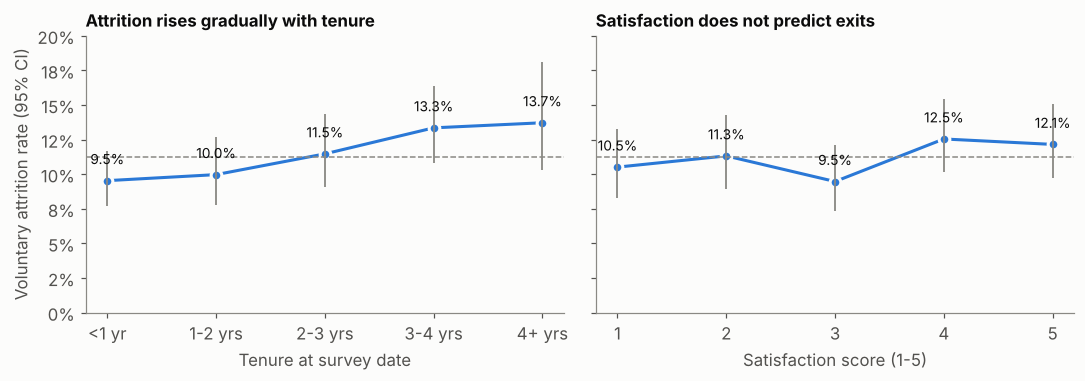

leavers    n   rate     lo     hi
tenure       <1 yr         81  850  0.095  0.077  0.117
             1-2 yrs       57  572  0.100  0.078  0.127
             2-3 yrs       65  567  0.115  0.091  0.143
             3-4 yrs       77  577  0.133  0.108  0.164
             4+ yrs        41  299  0.137  0.103  0.181
satisfaction 1             60  571  0.105  0.083  0.133
             2             61  539  0.113  0.089  0.143
             3             55  581  0.095  0.073  0.121
             4             76  606  0.125  0.101  0.154
             5             69  568  0.121  0.097  0.151

In [7]:
ten = rate_tbl("tenure_band", ["<1 yr", "1-2 yrs", "2-3 yrs", "3-4 yrs", "4+ yrs"])
sat = rate_tbl("Satisfaction Score", [1, 2, 3, 4, 5])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, t, title, xl in [(axes[0], ten, "Attrition rises gradually with tenure", "Tenure at survey date"),
                         (axes[1], sat, "Satisfaction does not predict exits", "Satisfaction score (1-5)")]:
    x = np.arange(len(t))
    ax.plot(x, t["rate"], color=BLUE, lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2)
    ax.vlines(x, t["lo"], t["hi"], color=GREY, lw=1.2)
    ax.axhline(overall, color=GREY, ls="--", lw=1)
    for xi, r in zip(x, t["rate"]):
        ax.text(xi, r + 0.012, f"{r:.1%}", ha="center", fontsize=9)
    ax.set_xticks(x, [str(i) for i in t.index])
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xl)
    ax.set_ylim(0, 0.2)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Voluntary attrition rate (95% CI)")
plt.tight_layout()
plt.savefig(FIG / "02_tenure_and_satisfaction.png", dpi=150)
plt.show()
pd.concat({"tenure": ten, "satisfaction": sat}).round(3)

**Reading the charts**

- Department and job title are where the differences are. Production (about 15%) and Software Engineering (about 18%, but only 112 people) are well above IT, Sales and Admin.
- Tenure shows a gradual rise (roughly 9.5% to 13.7%), not a spike in years 3 to 5. The intervals overlap heavily.
- Satisfaction shows no pattern. Employees scoring 1 or 2 leave no more often than employees scoring 4 or 5.

## 4. Features

**Excluded on purpose**

| Excluded | Reason |
|---|---|
| Gender, race, marital status | Protected attributes. Kept out of the model and used only to audit it. |
| DOB / age | Age is protected. Used only for the age-band audit. |
| Names, emails, supervisor, trainer, location codes | Identifiers, not drivers. |
| `EmployeeStatus`, `ExitDate`, `TerminationType`, `TerminationDescription` | These define or leak the label. |

**Included**: job and organisation (title group, department, division, business unit, employment type, pay zone, classification), survey scores, performance, training details, tenure at survey date, days between training and survey, and the two data-quality flags.

In [8]:
top_titles = df["Title"].value_counts().head(12).index
df["title_group"] = df["Title"].where(df["Title"].isin(top_titles), "Other")
df["tenure_neg_flag"] = (df["tenure_years"] < 0).astype(int)
df["train_after_survey_flag"] = (df["days_train_to_survey"] < 0).astype(int)

CAT = ["title_group", "DepartmentType", "Division", "BusinessUnit", "EmployeeType", "PayZone",
       "EmployeeClassificationType", "Performance Score", "Training Outcome", "Training Type"]
NUM = ["Current Employee Rating", "Engagement Score", "Satisfaction Score",
       "Work-Life Balance Score", "Training Duration(Days)", "Training Cost",
       "tenure_years", "days_train_to_survey", "tenure_neg_flag", "train_after_survey_flag"]
# Excluded on purpose: GenderCode, RaceDesc, MaritalDesc, DOB/age (protected attributes,
# used only to audit), names, emails, supervisor, trainer, location codes, exit fields (label).
FEATURES = CAT + NUM
X, y = df[FEATURES], df["left"]


def make_pre(scale: bool):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                              sparse_output=False), CAT),
        ("num", StandardScaler() if scale else "passthrough", NUM),
    ])


def candidates():
    return {
        "Baseline: department only": Pipeline([
            ("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"),
                                        ["DepartmentType"])])),
            ("clf", LogisticRegression(max_iter=1000))]),
        "Logistic regression (L2)": Pipeline([
            ("pre", make_pre(True)),
            ("clf", LogisticRegression(C=0.1, max_iter=2000))]),
        "Random forest": Pipeline([
            ("pre", make_pre(False)),
            ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=15, max_features="sqrt",
                                           class_weight="balanced_subsample", n_jobs=-1,
                                           random_state=SEED))]),
        "Gradient boosting": Pipeline([
            ("pre", make_pre(False)),
            ("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                   min_samples_leaf=30, l2_regularization=1.0,
                                                   random_state=SEED))]),
    }

## 5. Model selection (cross-validation on the training set only)

Four candidates are compared with 5-fold x 3-repeat stratified cross-validation on an 80% training split. The 20% test set is **not touched** until the model is chosen. A department-only logistic regression is the baseline: if a complex model cannot beat "which department are you in", it adds nothing.

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_rows = []
for name, pipe in candidates().items():
    aucs, aps = [], []
    for tr_i, va_i in rskf.split(X_tr, y_tr):
        pipe.fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
        p = pipe.predict_proba(X_tr.iloc[va_i])[:, 1]
        aucs.append(roc_auc_score(y_tr.iloc[va_i], p))
        aps.append(average_precision_score(y_tr.iloc[va_i], p))
    cv_rows.append({"model": name, "cv_auc_mean": np.mean(aucs), "cv_auc_sd": np.std(aucs),
                    "cv_pr_auc_mean": np.mean(aps), "cv_pr_auc_sd": np.std(aps)})
cv = pd.DataFrame(cv_rows).round(4)
cv.to_csv(OUT / "model_cv_results.csv", index=False)
print(cv.to_string(index=False))

contenders = cv[cv["model"] != "Baseline: department only"].sort_values("cv_auc_mean", ascending=False)
best_name = contenders.iloc[0]["model"]
summary["selected_model"] = best_name
print("Selected:", best_name)

                    model  cv_auc_mean  cv_auc_sd  cv_pr_auc_mean  cv_pr_auc_sd
Baseline: department only       0.6408     0.0210          0.1517        0.0090
 Logistic regression (L2)       0.7018     0.0234          0.2215        0.0362
            Random forest       0.7071     0.0257          0.2079        0.0295
        Gradient boosting       0.7041     0.0235          0.2154        0.0236
Selected: Random forest


The three full models are within noise of each other (they differ by less than one standard deviation). The random forest is selected on the highest mean AUC. All of them beat the department-only baseline, which tells us there is some signal beyond department.

## 6. One-time test evaluation

The selected model and the baseline are scored once on the held-out test set. Intervals come from a 1,000-resample bootstrap.

Instead of a probability threshold tuned on the test set, the operating point is a **capacity rule**: HR reviews the top 20% by risk score. Precision, recall and lift are reported at that point.

In [10]:
rng = np.random.default_rng(SEED)
test_rows = []
test_scores = {}
for name in ["Baseline: department only", best_name]:
    pipe = candidates()[name].fit(X_tr, y_tr)
    p = pipe.predict_proba(X_te)[:, 1]
    test_scores[name] = p
    boots = []
    for _ in range(1000):
        i = rng.integers(0, len(y_te), len(y_te))
        if y_te.iloc[i].nunique() == 2:
            boots.append(roc_auc_score(y_te.iloc[i], p[i]))
    k = int(np.ceil(len(y_te) * FLAG_TOP_PCT))
    top = np.argsort(-p)[:k]
    prec = y_te.iloc[top].mean()
    rec = y_te.iloc[top].sum() / y_te.sum()
    test_rows.append({"model": name, "test_auc": roc_auc_score(y_te, p),
                      "auc_ci_low": np.percentile(boots, 2.5), "auc_ci_high": np.percentile(boots, 97.5),
                      "test_pr_auc": average_precision_score(y_te, p),
                      f"precision_top{int(FLAG_TOP_PCT*100)}pct": prec,
                      f"recall_top{int(FLAG_TOP_PCT*100)}pct": rec,
                      f"lift_top{int(FLAG_TOP_PCT*100)}pct": prec / y_te.mean(),
                      "n_test": len(y_te), "n_test_leavers": int(y_te.sum()),
                      "base_rate": y_te.mean()})
test = pd.DataFrame(test_rows).round(4)
test.to_csv(OUT / "model_test_results.csv", index=False)
print(test.to_string(index=False))

                    model  test_auc  auc_ci_low  auc_ci_high  test_pr_auc  precision_top20pct  recall_top20pct  lift_top20pct  n_test  n_test_leavers  base_rate
Baseline: department only    0.6153      0.5761       0.6516       0.1409              0.1478           0.2656         1.3235     573              64     0.1117
            Random forest    0.6878      0.6252       0.7504       0.2174              0.2174           0.3906         1.9463     573              64     0.1117


The model beats the baseline, but the gain is moderate and the intervals overlap. Flagging the top 20% finds roughly 39% of leavers (about twice what random selection would). This is a prioritisation aid, not a precise predictor.

## 7. Out-of-fold risk scores and SHAP

Every employee gets a risk score from a model that **never saw that employee** (5-fold out-of-fold). This avoids the in-sample bias that would make current employees look safer than they are. SHAP values are computed on the same held-out folds, then summed back from one-hot columns to the original features.

The scores are for ranking, not probabilities: the forest is class-balanced, so raw values overstate absolute risk.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = pd.Series(np.nan, index=df.index)
shap_rows = []  # (index, feature) -> shap value, aggregated back to original features


def feature_groups(pre):
    names = pre.get_feature_names_out()
    groups = []
    for n in names:
        kind, rest = n.split("__", 1)
        if kind == "cat":
            base = next(c for c in sorted(CAT, key=len, reverse=True) if rest.startswith(c + "_"))
        else:
            base = rest
        groups.append(base)
    return np.array(groups)


all_shap = []
for tr_i, va_i in skf.split(X, y):
    pipe = candidates()[best_name].fit(X.iloc[tr_i], y.iloc[tr_i])
    oof.iloc[va_i] = pipe.predict_proba(X.iloc[va_i])[:, 1]
    pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
    Xtr_t = pre.transform(X.iloc[tr_i])
    Xva_t = pre.transform(X.iloc[va_i])
    if isinstance(clf, LogisticRegression):
        expl = shap.LinearExplainer(clf, Xtr_t)
        sv = expl.shap_values(Xva_t)
    else:
        expl = shap.TreeExplainer(clf)
        sv = expl.shap_values(Xva_t)
        if isinstance(sv, list):
            sv = sv[1]
        elif getattr(sv, "ndim", 2) == 3:
            sv = sv[:, :, 1]
    grp = feature_groups(pre)
    sv_df = pd.DataFrame(sv, index=X.index[va_i]).T.groupby(grp).sum().T
    all_shap.append(sv_df)
shap_df = pd.concat(all_shap).loc[X.index]
df["risk_score"] = oof
summary["oof_auc_full_cohort"] = round(roc_auc_score(y, oof), 4)

global_imp = shap_df.abs().mean().sort_values(ascending=False).rename("mean_abs_shap").reset_index()
global_imp.columns = ["feature", "mean_abs_shap"]
global_imp["rank"] = np.arange(1, len(global_imp) + 1)
global_imp.to_csv(OUT / "shap_global_importance.csv", index=False)
print(global_imp.head(10).to_string(index=False))

                   feature  mean_abs_shap  rank
            DepartmentType       0.083429     1
               title_group       0.066627     2
              tenure_years       0.018052     3
   Current Employee Rating       0.016699     4
      days_train_to_survey       0.015645     5
             Training Cost       0.013424     6
          Training Outcome       0.011230     7
                   PayZone       0.008094     8
                  Division       0.007689     9
EmployeeClassificationType       0.007066    10


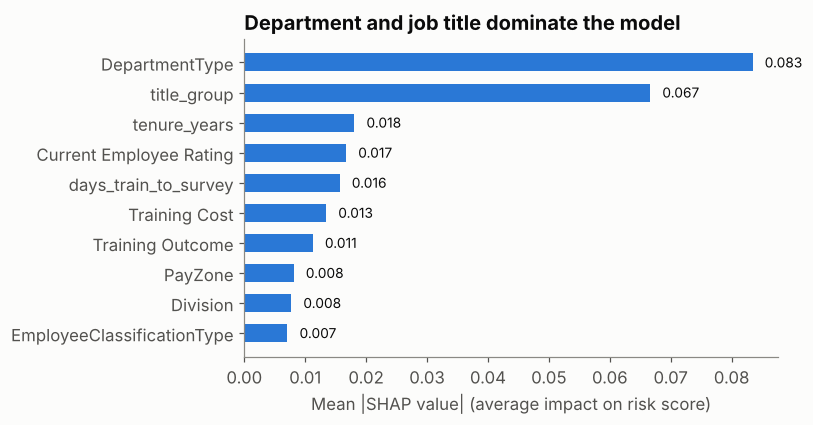

In [12]:
top = global_imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top["feature"], top["mean_abs_shap"], color=BLUE, height=0.6)
for i, v in enumerate(top["mean_abs_shap"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_title("Department and job title dominate the model")
ax.set_xlabel("Mean |SHAP value| (average impact on risk score)")
plt.tight_layout()
plt.savefig(FIG / "03_shap_global_importance.png", dpi=150)
plt.show()

Department and job title carry most of the signal. Satisfaction, engagement and work-life balance do not appear near the top, consistent with the flat pattern in section 3.

## 8. Risk bands and per-employee drivers

- Top 10% by out-of-fold risk = **High**, next 20% = **Medium**, rest = **Low**.
- The top 3 *risk-increasing* SHAP features for each employee become their drivers.
- The suggested action is looked up from the employee's **top SHAP driver**. It is a rule that depends on the model's reasoning, not a rule that decides the risk.

In [13]:
df["risk_pct_rank"] = df["risk_score"].rank(pct=True, method="first")
df["risk_band"] = np.select(
    [df["risk_pct_rank"] > 1 - HIGH_PCT, df["risk_pct_rank"] > 1 - MED_PCT], ["High", "Medium"], "Low")
df["flagged"] = (df["risk_pct_rank"] > 1 - FLAG_TOP_PCT).astype(int)

LABEL = {"title_group": "Job title", "DepartmentType": "Department", "Division": "Division",
         "BusinessUnit": "Business unit", "EmployeeType": "Employment type", "PayZone": "Pay zone",
         "EmployeeClassificationType": "Classification", "Performance Score": "Performance",
         "Training Outcome": "Training outcome", "Training Type": "Training type",
         "Current Employee Rating": "Rating", "Engagement Score": "Engagement",
         "Satisfaction Score": "Satisfaction", "Work-Life Balance Score": "Work-life balance",
         "Training Duration(Days)": "Training days", "Training Cost": "Training cost",
         "tenure_years": "Tenure (yrs)", "days_train_to_survey": "Days since training",
         "tenure_neg_flag": "Tenure data flag", "train_after_survey_flag": "Training date flag"}
ACTION = {"Job title": "Review workload, pay and progression for this job family",
          "Department": "Discuss team-level conditions with the department head",
          "Division": "Review division staffing and rostering",
          "Business unit": "Review unit-level conditions with the unit lead",
          "Employment type": "Review contract terms and conversion options",
          "Pay zone": "Benchmark pay against the market for this zone",
          "Classification": "Review classification and entitlements",
          "Performance": "Hold a performance and development conversation",
          "Training outcome": "Offer follow-up training support",
          "Training type": "Review training mix and relevance",
          "Rating": "Hold a career conversation with the manager",
          "Engagement": "Run a stay interview on engagement",
          "Satisfaction": "Run a stay interview on satisfaction",
          "Work-life balance": "Review hours and flexibility options",
          "Training days": "Review training load", "Training cost": "Review training investment",
          "Tenure (yrs)": "Hold a career-path check-in",
          "Days since training": "Schedule refresher training",
          "Tenure data flag": "Verify HR start-date record",
          "Training date flag": "Verify HR training-date record"}


def fmt(feat, row):
    v = row[feat]
    if feat in CAT:
        return str(v)
    if feat.endswith("_flag"):
        return "check record"
    return f"{v:.1f}" if isinstance(v, (float, np.floating)) else str(v)


drivers = []
for idx, row in df.iterrows():
    contrib = shap_df.loc[idx]
    top = contrib[contrib > 0].sort_values(ascending=False).head(3)
    drivers.append([(LABEL[f], fmt(f, row), round(float(v), 4)) for f, v in top.items()])
for k in range(3):
    df[f"driver_{k+1}"] = [d[k][0] + ": " + d[k][1] if len(d) > k else "" for d in drivers]
    df[f"driver_{k+1}_shap"] = [d[k][2] if len(d) > k else np.nan for d in drivers]
df["primary_driver_feature"] = [d[0][0] if d else "None" for d in drivers]
df["suggested_action"] = df["primary_driver_feature"].map(ACTION).fillna("No model-driven action")

In [14]:
current_preview = df[df["left"] == 0].sort_values("risk_score", ascending=False)
current_preview[["DepartmentType", "title_group", "risk_band", "driver_1", "driver_2", "driver_3",
                 "suggested_action"]].head(5)

,DepartmentType,title_group,risk_band,driver_1,driver_2,driver_3,suggested_action
2324,Production,Production Technician II,High,Job title: Production Technician II,Department: Production,Tenure (yrs): 4.2,"Review workload, pay and progression for this ..."
1000,Production,Production Technician II,High,Job title: Production Technician II,Department: Production,Tenure (yrs): 4.0,"Review workload, pay and progression for this ..."
1025,Production,Production Technician II,High,Job title: Production Technician II,Department: Production,Training outcome: Passed,"Review workload, pay and progression for this ..."
2732,Production,Production Technician II,High,Job title: Production Technician II,Department: Production,Tenure (yrs): 4.7,"Review workload, pay and progression for this ..."
2671,Production,Production Technician II,High,Job title: Production Technician II,Department: Production,Satisfaction: 5,"Review workload, pay and progression for this ..."


In [15]:
# How well does the model rank people *within* the biggest department?
prod = df[df["DepartmentType"] == "Production"]
summary["within_production_auc"] = round(roc_auc_score(prod["left"], prod["risk_score"]), 3)
print("Within-Production out-of-fold AUC:", summary["within_production_auc"],
      f'(n={len(prod):,}, leavers={int(prod["left"].sum())})')

Within-Production out-of-fold AUC: 0.6 (n=1,944, leavers=287)


## 9. Exports for Tableau

Employee keys are salted hashes. Names, emails and protected attributes are left out of the employee-level file.

In [16]:
df["employee_key"] = df["Employee ID"].astype(str).map(
    lambda s: hashlib.sha256(("attrition-demo-" + s).encode()).hexdigest()[:8])
df["tenure_band"] = pd.cut(df["tenure_years"].clip(lower=0), [-0.01, 1, 2, 3, 4, 10],
                           labels=["<1 yr", "1-2 yrs", "2-3 yrs", "3-4 yrs", "4+ yrs"]).astype(str)
df["age_band"] = pd.cut(df["age"], [0, 30, 40, 50, 60, 100],
                        labels=["<30", "30-39", "40-49", "50-59", "60+"]).astype(str)

emp_cols = ["employee_key", "DepartmentType", "title_group", "Title", "Division", "EmployeeType",
            "tenure_years", "tenure_band", "Performance Score", "Current Employee Rating",
            "Engagement Score", "Satisfaction Score", "Work-Life Balance Score", "risk_score",
            "risk_pct_rank", "risk_band", "flagged", "driver_1", "driver_2", "driver_3",
            "primary_driver_feature", "suggested_action"]
current = df[df["left"] == 0]
current[emp_cols].round(4).to_csv(OUT / "tableau_employee_risk.csv", index=False)

hist_cols = ["employee_key", "DepartmentType", "title_group", "Division", "EmployeeType",
             "tenure_years", "tenure_band", "Performance Score", "Satisfaction Score",
             "Engagement Score", "Work-Life Balance Score", "left", "risk_score", "risk_band"]
df[hist_cols].round(4).to_csv(OUT / "tableau_attrition_history.csv", index=False)

## 10. Fairness audit

**Setup.** "Flagged" means in the top 20% of out-of-fold risk. The model never sees gender, race or age.

**Which ratio?** The EEOC four-fifths rule compares rates of a *favourable* outcome. Being flagged leads to HR attention, so the favourable outcome is **not being flagged**. Both views are reported:

- `dir_favourable_vs_best`: not-flagged rate divided by the best group's not-flagged rate (pass if at least 0.8).
- `ratio_adverse_lowest_vs_group`: lowest flag rate divided by the group's flag rate.

The two can tell different stories when the flag rate is low overall, so showing one alone would be selective.

In [17]:
def audit(frame, col):
    rows = []
    for g, s in frame.groupby(col):
        n, flagged = len(s), int(s["flagged"].sum())
        pos, neg = int(s["left"].sum()), int((1 - s["left"]).sum())
        tp = int(((s["flagged"] == 1) & (s["left"] == 1)).sum())
        fp = int(((s["flagged"] == 1) & (s["left"] == 0)).sum())
        lo, hi = wilson(flagged, n)
        rows.append({"attribute": col, "group": g, "n": n, "actual_leavers": pos,
                     "actual_attrition_rate": pos / n, "flagged": flagged, "flag_rate": flagged / n,
                     "flag_rate_ci_low": lo, "flag_rate_ci_high": hi,
                     "not_flagged_rate": 1 - flagged / n,
                     "tpr": tp / pos if pos else np.nan, "fpr": fp / neg if neg else np.nan,
                     "precision": tp / flagged if flagged else np.nan})
    out = pd.DataFrame(rows)
    # EEOC four-fifths rule applied to the FAVOURABLE outcome (not being flagged),
    # reference = group with the highest not-flagged rate.
    out["dir_favourable_vs_best"] = out["not_flagged_rate"] / out["not_flagged_rate"].max()
    # Same ratio on the adverse outcome (flag rate), lowest flag rate / group flag rate.
    out["ratio_adverse_lowest_vs_group"] = out["flag_rate"].min() / out["flag_rate"]
    out["four_fifths_pass"] = out["dir_favourable_vs_best"] >= 0.8
    out["small_group_warning"] = out["n"] < 300
    return out


fair = pd.concat([audit(df, "GenderCode"), audit(df, "RaceDesc"), audit(df, "age_band")])
fair["metric_note"] = "Flagged = top 20% of out-of-fold risk scores; model excludes gender, race, age."
fair.round(4).to_csv(OUT / "tableau_fairness_audit.csv", index=False)
print(fair[["attribute", "group", "n", "flag_rate", "actual_attrition_rate", "dir_favourable_vs_best",
            "ratio_adverse_lowest_vs_group", "tpr", "fpr"]].round(3).to_string(index=False))

# gender gap within department: is it job mix?
dg = []
for dept, s in df.groupby("DepartmentType"):
    for g, t in s.groupby("GenderCode"):
        dg.append({"DepartmentType": dept, "GenderCode": g, "n": len(t),
                   "flag_rate": t["flagged"].mean(), "actual_attrition_rate": t["left"].mean()})
dg = pd.DataFrame(dg)
dg.round(4).to_csv(OUT / "tableau_fairness_by_department.csv", index=False)
comp = pd.crosstab(df["DepartmentType"], df["GenderCode"], normalize="columns").round(3)
print("\nDepartment mix by gender (share of each gender):\n", comp)
print(dg[dg["n"] >= 30].round(3).to_string(index=False))

# bootstrap CI on gender DIR (favourable outcome)
def gender_dir(frame):
    r = frame.groupby("GenderCode")["flagged"].mean()
    nf = 1 - r
    return nf.min() / nf.max()

bs = []
for _ in range(1000):
    bs.append(gender_dir(df.sample(len(df), replace=True, random_state=int(rng.integers(1e9)))))
summary["gender_dir_favourable"] = round(gender_dir(df), 4)
summary["gender_dir_ci"] = [round(float(np.percentile(bs, 2.5)), 4), round(float(np.percentile(bs, 97.5)), 4)]
summary["gender_flag_rate_ratio_adverse"] = round(
    float(df.groupby("GenderCode")["flagged"].mean().min() / df.groupby("GenderCode")["flagged"].mean().max()), 4)

 attribute    group    n  flag_rate  actual_attrition_rate  dir_favourable_vs_best  ratio_adverse_lowest_vs_group   tpr   fpr
GenderCode   Female 1606      0.243                  0.126                   0.886                          0.599 0.401 0.220
GenderCode     Male 1259      0.145                  0.095                   1.000                          1.000 0.328 0.126
  RaceDesc    Asian  599      0.200                  0.112                   0.980                          0.920 0.254 0.194
  RaceDesc    Black  586      0.184                  0.097                   1.000                          1.000 0.368 0.164
  RaceDesc Hispanic  546      0.198                  0.106                   0.983                          0.932 0.414 0.172
  RaceDesc    Other  555      0.196                  0.121                   0.985                          0.938 0.448 0.162
  RaceDesc    White  579      0.221                  0.124                   0.955                          0.834 0.38

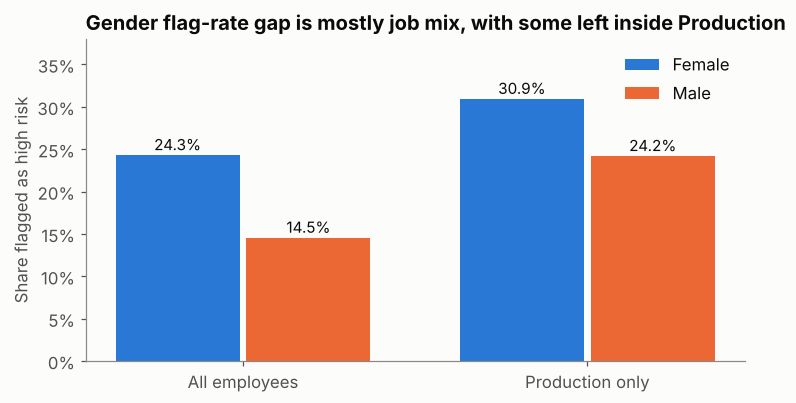

In [18]:
g = df.groupby("GenderCode")["flagged"].mean()
gp = df[df["DepartmentType"] == "Production"].groupby("GenderCode")["flagged"].mean()
labels, fem, mal = ["All employees", "Production only"], [g["Female"], gp["Female"]], [g["Male"], gp["Male"]]
x = np.arange(2)
fig, ax = plt.subplots(figsize=(7, 3.8))
b1 = ax.bar(x - 0.19, fem, 0.36, color=BLUE, label="Female")
b2 = ax.bar(x + 0.19, mal, 0.36, color=ORANGE, label="Male")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.006, f"{b.get_height():.1%}", ha="center", fontsize=10)
ax.set_xticks(x, labels)
ax.set_ylim(0, 0.38)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share flagged as high risk")
ax.set_title("Gender flag-rate gap is mostly job mix, with some left inside Production")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "04_gender_flag_rate.png", dpi=150)
plt.show()

**Reading the audit**

- **Gender** is the one gap that matters. Women are flagged more often than men. Measured on the favourable outcome the ratio is about 0.89 (above 0.8, so it passes, but it is in the "watch" zone). Measured on the flag rate itself, it is about 0.60.
- **Why.** About 76% of women work in Production versus about 58% of men, and Production has the highest attrition. Much of the gap is job mix. A smaller gap remains *inside* Production, partly because women in Production actually leave more often in this data.
- **Race and age**: no group falls below 0.94 on the favourable-outcome ratio.
- **Small cells** (for example Software Engineering by gender, 46 and 66 people) are too small to conclude anything. They are shown for transparency, not as findings.

## 11. Fairness versus accuracy

If the gap comes from job structure, removing the job-structure features should close it. This tests that directly by refitting without title, department, division and business unit.

In [19]:
JOB = ["title_group", "DepartmentType", "Division", "BusinessUnit"]
variants = {"Full model": CAT,
            "Without job-structure features (title, dept, division, business unit)": [c for c in CAT if c not in JOB]}
trade_rows = []
for vname, cat in variants.items():
    pipe = Pipeline([
        ("pre", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), cat),
            ("num", "passthrough", NUM)])),
        ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=15, max_features="sqrt",
                                       class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
    Xv, oof_v = df[cat + NUM], pd.Series(np.nan, index=df.index)
    for tr_i, va_i in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xv, df["left"]):
        pipe.fit(Xv.iloc[tr_i], df["left"].iloc[tr_i])
        oof_v.iloc[va_i] = pipe.predict_proba(Xv.iloc[va_i])[:, 1]
    flag_v = oof_v.rank(pct=True, method="first") > 1 - FLAG_TOP_PCT
    fr = flag_v.groupby(df["GenderCode"]).mean()
    rec = (flag_v & (df["left"] == 1)).groupby(df["GenderCode"]).sum() / df.groupby("GenderCode")["left"].sum()
    trade_rows.append({"variant": vname, "oof_auc": round(roc_auc_score(df["left"], oof_v), 3),
                       "flag_rate_female": round(fr["Female"], 3), "flag_rate_male": round(fr["Male"], 3),
                       "flag_rate_ratio_male_over_female": round(fr.min() / fr.max(), 3),
                       "dir_favourable_not_flagged": round((1 - fr).min() / (1 - fr).max(), 3),
                       "recall_female": round(rec["Female"], 3), "recall_male": round(rec["Male"], 3)})
trade = pd.DataFrame(trade_rows)
trade.to_csv(OUT / "fairness_accuracy_tradeoff.csv", index=False)
trade.set_index("variant").T

variant,Full model,"Without job-structure features (title, dept, division, business unit)"
oof_auc,0.705,0.520
flag_rate_female,0.243,0.201
flag_rate_male,0.145,0.199
flag_rate_ratio_male_over_female,0.599,0.987
dir_favourable_not_flagged,0.886,0.997
recall_female,0.401,0.203
recall_male,0.328,0.244


Removing the job-structure features closes the gender gap (ratio near 1.0) but the model's AUC falls to about 0.52, which is chance. In this dataset the information that makes the model useful is the same information that produces the gender disparity. There is no mitigation that keeps the accuracy and removes the gap, and **no group-specific thresholds were applied**, since using different thresholds by gender would itself be disparate treatment in an employment setting. The practical safeguard is human review of every flag.

## 12. Attrition rate tables and run summary

In [20]:
def rate_table(col):
    rows = []
    for g, s in df.groupby(col):
        k, n = int(s["left"].sum()), len(s)
        lo, hi = wilson(k, n)
        rows.append({"dimension": col, "group": g, "n": n, "leavers": k, "attrition_rate": k / n,
                     "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


rates = pd.concat([rate_table(c) for c in ["DepartmentType", "title_group", "tenure_band",
                                           "Satisfaction Score", "Engagement Score",
                                           "Work-Life Balance Score", "Performance Score"]])
rates.round(4).to_csv(OUT / "tableau_attrition_rates.csv", index=False)
print(rates[rates.dimension.isin(["tenure_band", "Satisfaction Score"])].round(3).to_string(index=False))

summary["current_employees_scored"] = len(current)
summary["high_risk_current"] = int((current["risk_band"] == "High").sum())
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

         dimension   group   n  leavers  attrition_rate  ci_low  ci_high
       tenure_band 1-2 yrs 572       57           0.100   0.078    0.127
       tenure_band 2-3 yrs 567       65           0.115   0.091    0.143
       tenure_band 3-4 yrs 577       77           0.133   0.108    0.164
       tenure_band  4+ yrs 299       41           0.137   0.103    0.181
       tenure_band   <1 yr 850       81           0.095   0.077    0.117
Satisfaction Score       1 571       60           0.105   0.083    0.133
Satisfaction Score       2 539       61           0.113   0.089    0.143
Satisfaction Score       3 581       55           0.095   0.073    0.121
Satisfaction Score       4 606       76           0.125   0.101    0.154
Satisfaction Score       5 568       69           0.121   0.097    0.151
{
  "rows_raw": 3150,
  "exact_duplicate_rows_removed": 150,
  "dq_negative_tenure_rows": 287,
  "dq_training_after_survey_rows": 1480,
  "dq_status_active_but_has_exit_date": 991,
  "cohort_rows":

## Limitations

- **Synthetic data.** The relationships are simulated. The method transfers; the findings do not.
- **No time window.** The label is "has left", so the score ranks resemblance to past leavers, not 6-month risk.
- **Contradictory fields.** Status, exit date and termination type disagree. The label depends on `EmployeeStatus` alone.
- **Moderate signal.** Test AUC is about 0.69 with a wide interval. Within the Production department the ranking AUC is only about 0.60. Treat results as a prioritisation aid for conversations, never as a basis for decisions about individuals.
- **Small cells.** Software Engineering and several department-by-gender groups are too small for firm conclusions.
- **Fairness scope.** Gender, race and age band were audited. Intersections and other attributes were not.